# 06 — RR-ES δ Sensitivity across Environments

Justifies our choice of δ=1 as the default in the main experiments.
Shows how sensitive RR-ES is to δ on each environment.


In [1]:
import sys, os, time
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from envs import (CliffWalking, StochasticCliff,
                  CorridorCliff, StochasticCorridorCliff)
from agents import (run_sarsa, run_q_learning, run_expected_sarsa,
                    run_double_expected_sarsa, run_rr_expected_sarsa)
from utils import (multi_seed_run, smooth,
                   bootstrap_mean_ci, bootstrap_diff_ci, pairwise_table,
                   rollout_metrics, regret_to_convergence)

# ---- Run configuration ----
# Set N_RUNS=50 for pilot, bump to 500 for final overnight run
N_RUNS = 50
N_EPISODES = 100
EPS_DEFAULT = 0.1
ALPHA_DEFAULT = 0.3
SLIP = 0.2
RR_DELTA = 1.0   # RR-ES regret threshold used in most experiments

def sem(arr, axis=0):
    return arr.std(axis=axis, ddof=1) / np.sqrt(arr.shape[axis])

# ---- Environment factories ----
def env_det(seed=None):   return CliffWalking()
def env_stoch(seed=None): return StochasticCliff(slip_prob=SLIP, rng_seed=seed)
def env_corr(seed=None):  return CorridorCliff()
def env_scor(seed=None):  return StochasticCorridorCliff(slip_prob=SLIP, rng_seed=seed)

ENVS = {
    'Det Cliff':        env_det,
    'Stoch Cliff':      env_stoch,
    'Corr Cliff':       env_corr,
    'Stoch Corr Cliff': env_scor,
}

# ---- Method registry ----
METHODS = {
    'SARSA':          (run_sarsa,                {}),
    'Q-learning':     (run_q_learning,           {}),
    'Expected SARSA': (run_expected_sarsa,       {}),
    'Double ES':      (run_double_expected_sarsa, {}),
    f'RR-ES (δ={RR_DELTA})': (run_rr_expected_sarsa, {'delta': RR_DELTA}),
}

METHOD_COLORS = {
    'SARSA':              '#1f77b4',
    'Q-learning':         '#ff7f0e',
    'Expected SARSA':     '#2ca02c',
    'Double ES':          '#9467bd',
    f'RR-ES (δ={RR_DELTA})': '#d62728',
}
METHOD_MARKERS = {
    'SARSA':              'o',
    'Q-learning':         's',
    'Expected SARSA':     '^',
    'Double ES':          'v',
    f'RR-ES (δ={RR_DELTA})': 'D',
}


In [2]:
DELTAS = np.array([0.1, 0.3, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0, 30.0, 100.0])

rr_results = {env_name: {'mean': np.zeros(len(DELTAS)),
                         'sem':  np.zeros(len(DELTAS))}
              for env_name in ENVS}

# baseline: ES on each env (horizontal ref line)
es_baseline = {}
t0 = time.time()
for env_name, env_fn in ENVS.items():
    print(f'\n=== {env_name} ===')
    es_ret = multi_seed_run(run_expected_sarsa, env_fn, N_RUNS, N_EPISODES,
                             alpha=ALPHA_DEFAULT, eps=EPS_DEFAULT,
                             progress=True, desc='ES baseline')
    es_per_run = es_ret[:, -30:].mean(axis=1)
    es_baseline[env_name] = {'mean': es_per_run.mean(),
                              'sem':  es_per_run.std(ddof=1) / np.sqrt(N_RUNS)}
    for i, d in enumerate(DELTAS):
        ret = multi_seed_run(run_rr_expected_sarsa, env_fn, N_RUNS, N_EPISODES,
                             alpha=ALPHA_DEFAULT, eps=EPS_DEFAULT, delta=d,
                             progress=True, desc=f'δ={d}')
        per_run = ret[:, -30:].mean(axis=1)
        rr_results[env_name]['mean'][i] = per_run.mean()
        rr_results[env_name]['sem'][i]  = per_run.std(ddof=1) / np.sqrt(N_RUNS)
print(f'\ntotal: {time.time()-t0:.0f}s')



=== Det Cliff ===


ES baseline:   0%|          | 0/50 [00:00<?, ?it/s]

δ=0.1:   0%|          | 0/50 [00:00<?, ?it/s]

δ=0.3:   0%|          | 0/50 [00:00<?, ?it/s]

δ=0.5:   0%|          | 0/50 [00:00<?, ?it/s]

δ=1.0:   0%|          | 0/50 [00:00<?, ?it/s]

... (39 outputs left out)

δ=10.0:   0%|          | 0/50 [00:00<?, ?it/s]

δ=30.0:   0%|          | 0/50 [00:00<?, ?it/s]

δ=100.0:   0%|          | 0/50 [00:00<?, ?it/s]


total: 235s


In [3]:
safe = lambda s: s.replace(' ', '_').replace('(','').replace(')','').replace('=','_').replace('δ','delta')
np.savez('../results/data/06_delta_sensitivity.npz',
         deltas=DELTAS, n_runs=N_RUNS,
         **{f'{safe(k)}__{stat}': v[stat] for k, v in rr_results.items() for stat in ['mean', 'sem']},
         **{f'es_baseline__{safe(k)}__{stat}': v[stat] for k, v in es_baseline.items() for stat in ['mean', 'sem']})
print('saved')


saved


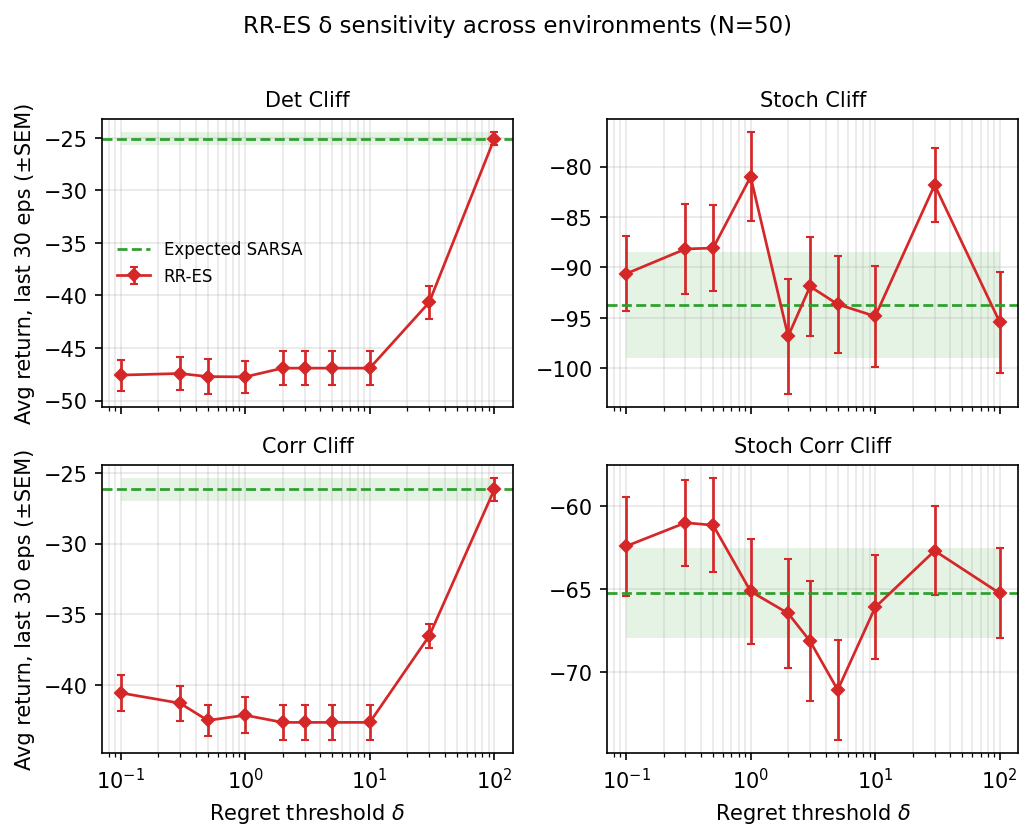

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5.5), dpi=150, sharex=True)
axes = axes.flatten()
for ax, (env_name, d) in zip(axes, rr_results.items()):
    ax.errorbar(DELTAS, d['mean'], yerr=d['sem'],
                marker='D', color='#d62728', linewidth=1.3, markersize=4, capsize=2,
                label='RR-ES')
    es = es_baseline[env_name]
    ax.axhline(es['mean'], color='#2ca02c', linestyle='--', linewidth=1.3, label='Expected SARSA')
    ax.fill_between([DELTAS[0], DELTAS[-1]],
                    es['mean'] - es['sem'], es['mean'] + es['sem'],
                    color='#2ca02c', alpha=0.12, linewidth=0)
    ax.set_xscale('log')
    ax.set_title(env_name, fontsize=10)
    ax.grid(alpha=0.3, which='both')
axes[0].set_ylabel('Avg return, last 30 eps (±SEM)')
axes[2].set_ylabel('Avg return, last 30 eps (±SEM)')
axes[2].set_xlabel(r'Regret threshold $\delta$'); axes[3].set_xlabel(r'Regret threshold $\delta$')
axes[0].legend(frameon=False, fontsize=8)
plt.suptitle(f'RR-ES δ sensitivity across environments (N={N_RUNS})', y=1.01, fontsize=11)
plt.tight_layout()
plt.savefig('../results/figures/06_delta_sensitivity.png', dpi=200, bbox_inches='tight')
plt.show()
